In [1]:
import numpy as np 
import pandas as pd

In [2]:
pd.set_option("display.max_columns", 400)

In [3]:
diabetic_data = pd.read_csv("./Data/diabetic_data.csv")
diabetic_features = pd.read_csv("./Data/diabetes_features.csv")
ids_mapping = pd.read_csv("./Data/IDS_mapping.csv")

In [4]:
diabetic_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [5]:
diabetic_data.head(2)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30


In [6]:
diabetic_features.shape

(28, 3)

In [7]:
for i in range(diabetic_features.shape[0]):
    print("="*100)
    print(diabetic_features.iloc[i,0])
    print(diabetic_features.iloc[i,1])
    print(diabetic_features.iloc[i,2])

Encounter ID
Numeric
Unique identifier of an encounter
Patient number
Numeric
Unique identifier of a patient
Race
Nominal
Values: Caucasian, Asian, African American, Hispanic, and other
Gender
Nominal
Values: male, female, and unknown/invalid
Age
Nominal
Grouped in 10-year intervals: [0, 10), [10, 20), …, [90, 100)
Weight
Numeric
Weight in pounds.
Admission type
Nominal
Integer identifier corresponding to 9 distinct values, for example, emergency, urgent, elective, newborn, and not available
Discharge disposition
Nominal
Integer identifier corresponding to 29 distinct values, for example, discharged to home, expired, and not available
Admission source
Nominal
Integer identifier corresponding to 21 distinct values, for example, physician referral, emergency room, and transfer from a hospital
Time in hospital
Numeric
Integer number of days between admission and discharge
Payer code
Nominal
Integer identifier corresponding to 23 distinct values, for example, Blue Cross/Blue Shield, Medica

In [8]:
from io import StringIO

with open("./Data/IDS_mapping.csv", "r", encoding="utf-8") as f:
    sections = f.read().split("\n,\n")

df1, df2, df3 = [
    pd.read_csv(StringIO(section.strip()))
    for section in sections
]

In [9]:
df1

,admission_type_id,description
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available
5,6,NaN
6,7,Trauma Center
7,8,Not Mapped


In [10]:
df2

,discharge_disposition_id,description
0,1,Discharged to home
1,2,Discharged/transferred to another short term h...
2,3,Discharged/transferred to SNF
3,4,Discharged/transferred to ICF
4,5,Discharged/transferred to another type of inpa...
5,6,Discharged/transferred to home with home healt...
6,7,Left AMA
7,8,Discharged/transferred to home under care of H...
8,9,Admitted as an inpatient to this hospital
9,10,Neonate discharged to another hospital for neo...


In [11]:
df3

,admission_source_id,description
0,1,Physician Referral
1,2,Clinic Referral
2,3,HMO Referral
3,4,Transfer from a hospital
4,5,Transfer from a Skilled Nursing Facility (SNF)
5,6,Transfer from another health care facility
6,7,Emergency Room
7,8,Court/Law Enforcement
8,9,Not Available
9,10,Transfer from critial access hospital


In [12]:
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   admission_source_id  25 non-null     int64 
 1   description          24 non-null     object
dtypes: int64(1), object(1)
memory usage: 532.0+ bytes


## Putting the admission type ID in the main dataframe

In [13]:
diabetic_data = diabetic_data.merge(df3.rename(columns={"description": "description_admissions_source"}), 
                    on="admission_source_id", how="inner")
diabetic_data = diabetic_data.merge(df2.rename(columns={"description": "description_discharge_disposition"}), 
                    on="discharge_disposition_id", how="inner")
diabetic_data = diabetic_data.merge(df1.rename(columns={"description": "description_admission_type"}), 
                    on="admission_type_id", how="inner")

In [14]:
diabetic_data

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,description_admissions_source,description_discharge_disposition,description_admission_type
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO,Physician Referral,Not Mapped,NaN
1,1968528,720936,Caucasian,Female,[70-80),?,6,25,1,10,?,Surgery-Cardiovascular/Thoracic,56,2,24,0,0,0,440,413,250.52,9,NaN,>7,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,>30,Physician Referral,Not Mapped,NaN
2,2223336,558360,AfricanAmerican,Female,[60-70),?,6,25,1,9,?,Orthopedics-Reconstructive,60,5,17,0,0,0,997,8,730,8,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO,Physician Referral,Not Mapped,NaN
3,2298006,2519748,Caucasian,Male,[60-70),?,6,25,1,4,?,InternalMedicine,47,0,15,0,0,0,486,250,427,8,NaN,NaN,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,NO,Physician Referral,Not Mapped,NaN
4,2356308,608841,AfricanAmerican,Female,[50-60),?,6,25,1,1,?,Family/GeneralPractice,50,0,8,0,0,0,250.03,401,276,8,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes,>30,Physician Referral,Not Mapped,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101761,249703860,71494254,Caucasian,Male,[40-50),?,7,11,7,1,HM,?,36,0,8,0,0,0,803,348,E812,5,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes,NO,Emergency Room,Expired,Trauma Center
101762,343730600,141434069,Caucasian,Female,[80-90),?,7,11,7,1,MC,?,1,2,5,0,0,0,430,432,250,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes,NO,Emergency Room,Expired,Trauma Center
101763,162365280,59456412,Caucasian,Female,[50-60),?,7,22,7,11,CP,?,70,6,29,0,0,0,821,518,821,9,NaN,Norm,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,NO,Emergency Room,Discharged/transferred to another rehab fac in...,Trauma Center
101764,182808666,59986746,Caucasian,Male,[50-60),?,7,22,7,8,CP,?,69,2,26,0,0,0,821,850,427,9,NaN,Norm,Steady,No,No,No,Steady,No,No,No,No,Steady,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO,Emergency Room,Discharged/transferred to another rehab fac in...,Trauma Center


In [15]:
import sqlite3
import pandas as pd

# Create or connect to SQLite database
conn = sqlite3.connect("database.db")

# Write DataFrame to SQLite table
diabetic_data.to_sql(
    name="diabetic_data",
    con=conn,
    if_exists="replace",
    index=False
)

101766

In [16]:
query = """
SELECT *
FROM diabetic_data
LIMIT 10
"""

result = pd.read_sql_query(query, conn)

display(result)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,description_admissions_source,description_discharge_disposition,description_admission_type
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO,Physician Referral,Not Mapped,None
1,1968528,720936,Caucasian,Female,[70-80),?,6,25,1,10,?,Surgery-Cardiovascular/Thoracic,56,2,24,0,0,0,440,413,250.52,9,None,>7,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,>30,Physician Referral,Not Mapped,None
2,2223336,558360,AfricanAmerican,Female,[60-70),?,6,25,1,9,?,Orthopedics-Reconstructive,60,5,17,0,0,0,997,8,730,8,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO,Physician Referral,Not Mapped,None
3,2298006,2519748,Caucasian,Male,[60-70),?,6,25,1,4,?,InternalMedicine,47,0,15,0,0,0,486,250,427,8,None,None,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,NO,Physician Referral,Not Mapped,None
4,2356308,608841,AfricanAmerican,Female,[50-60),?,6,25,1,1,?,Family/GeneralPractice,50,0,8,0,0,0,250.03,401,276,8,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes,>30,Physician Referral,Not Mapped,None
5,2363592,1059561,Caucasian,Female,[50-60),?,6,25,1,1,?,Cardiology,1,6,8,0,0,0,414,340,401,5,None,None,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO,Physician Referral,Not Mapped,None
6,2398146,8147493,Caucasian,Male,[60-70),?,6,25,1,1,?,Cardiology,31,2,8,0,0,0,414,496,401,5,None,None,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO,Physician Referral,Not Mapped,None
7,2422806,3377124,Caucasian,Male,[40-50),?,6,25,1,14,?,InternalMedicine,41,1,18,0,0,0,730,998,250,4,None,None,Steady,No,No,No,No,No,Steady,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Ch,Yes,>30,Physician Referral,Not Mapped,None
8,2466036,4311585,Caucasian,Male,[60-70),?,6,25,1,10,?,Cardiology,46,6,23,0,0,0,414,276,276,9,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,>30,Physician Referral,Not Mapped,None
9,2473188,981198,Caucasian,Female,[60-70),?,6,25,1,5,?,Nephrology,47,3,24,0,0,0,250.4,403,276,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes,>30,Physician Referral,Not Mapped,None


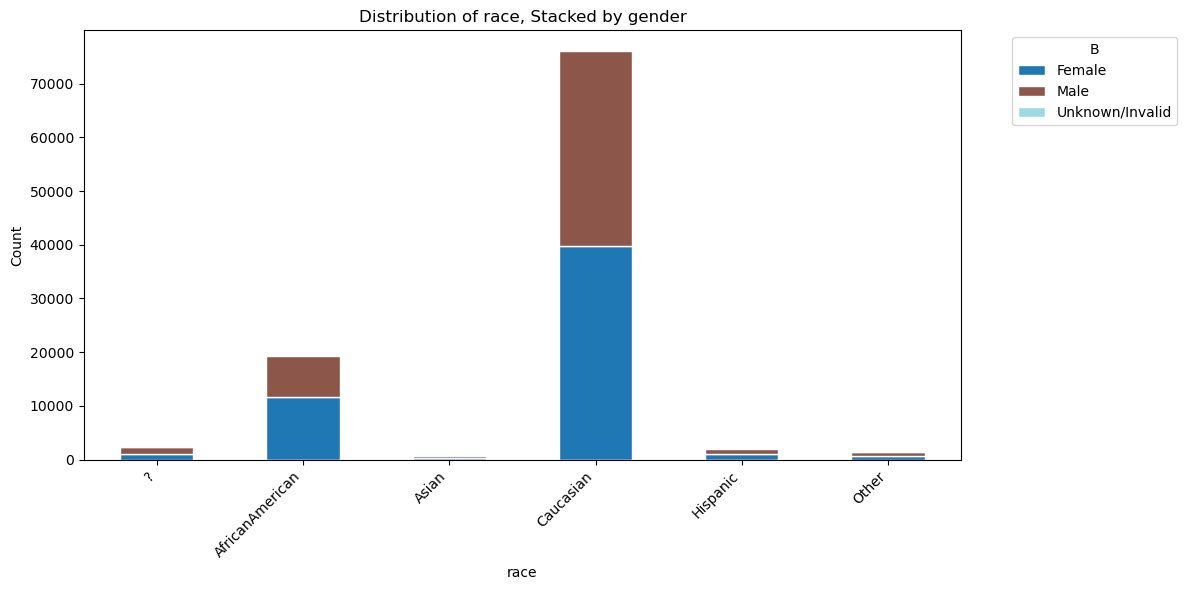

In [17]:
import matplotlib.pyplot as plt

# Count combinations of A and B
counts = pd.crosstab(diabetic_data["race"], diabetic_data["gender"])

# Plot stacked bar chart
ax = counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="tab20",
    edgecolor="white"
)

ax.set_xlabel("race")
ax.set_ylabel("Count")
ax.set_title("Distribution of race, Stacked by gender")
ax.legend(title="B", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

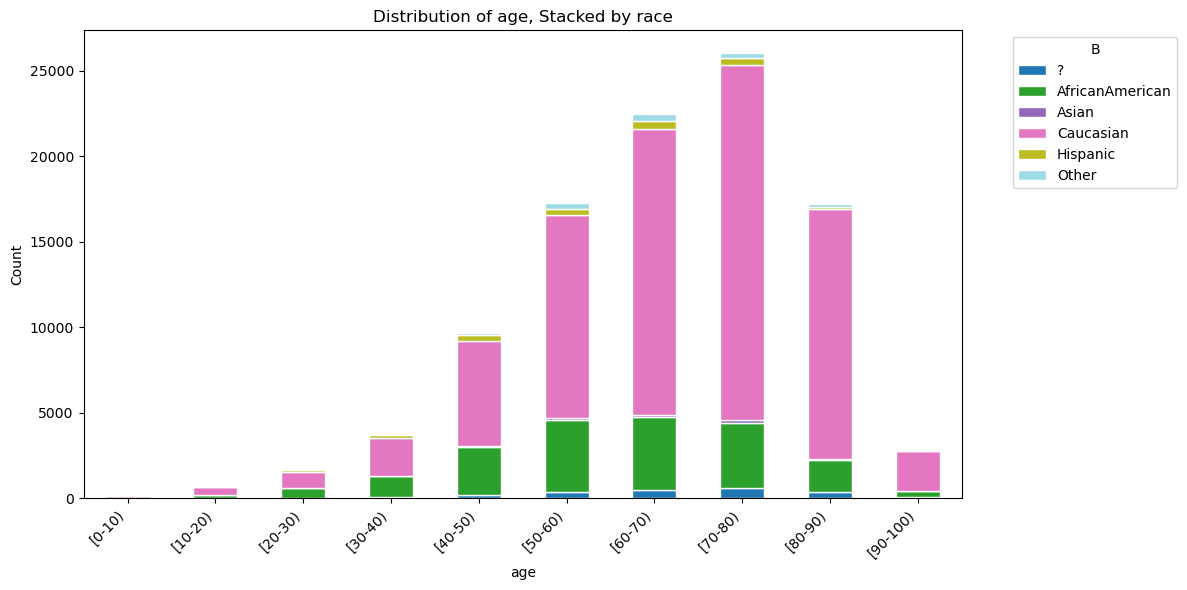

In [18]:
counts = pd.crosstab(diabetic_data["age"], diabetic_data["race"])

# Plot stacked bar chart
ax = counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="tab20",
    edgecolor="white"
)

ax.set_xlabel("age")
ax.set_ylabel("Count")
ax.set_title("Distribution of age, Stacked by race")
ax.legend(title="B", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

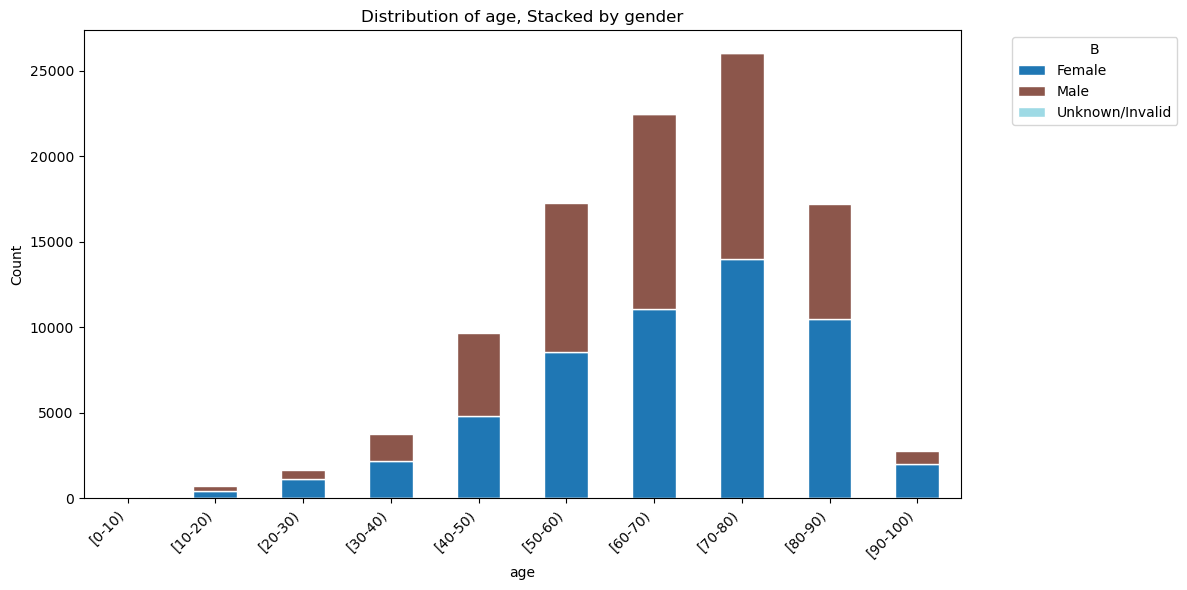

In [19]:
counts = pd.crosstab(diabetic_data["age"], diabetic_data["gender"])

# Plot stacked bar chart
ax = counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="tab20",
    edgecolor="white"
)

ax.set_xlabel("age")
ax.set_ylabel("Count")
ax.set_title("Distribution of age, Stacked by gender")
ax.legend(title="B", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

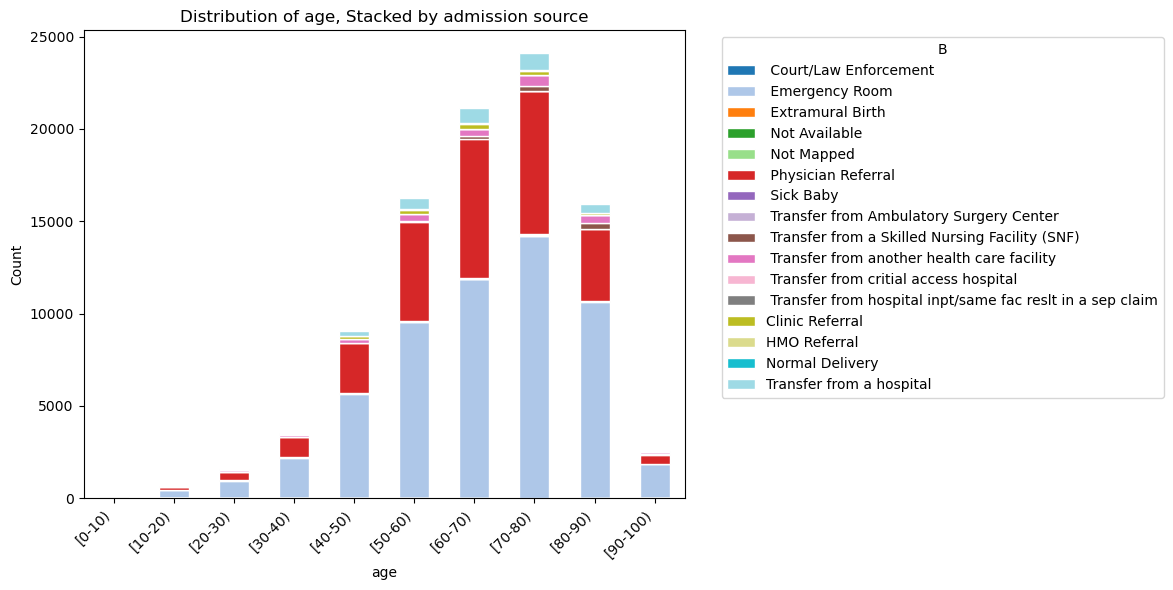

In [20]:
counts = pd.crosstab(diabetic_data["age"], diabetic_data["description_admissions_source"])

# Plot stacked bar chart
ax = counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="tab20",
    edgecolor="white"
)

ax.set_xlabel("age")
ax.set_ylabel("Count")
ax.set_title("Distribution of age, Stacked by admission source")
ax.legend(title="B", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

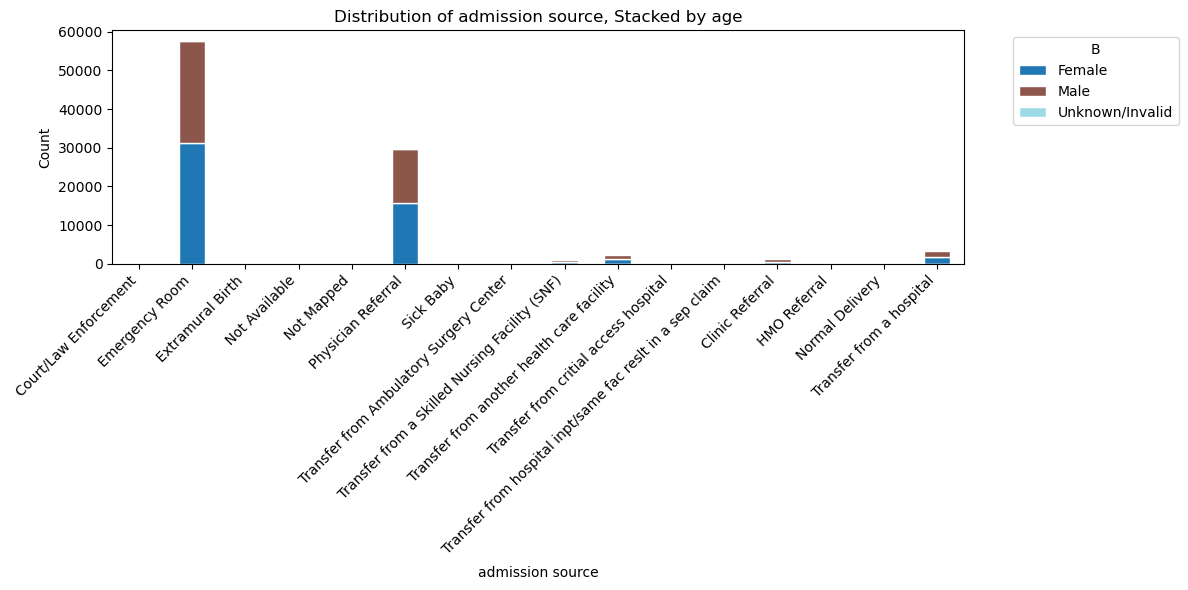

In [21]:
counts = pd.crosstab(diabetic_data["description_admissions_source"], diabetic_data["gender"])

# Plot stacked bar chart
ax = counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="tab20",
    edgecolor="white"
)

ax.set_xlabel("admission source")
ax.set_ylabel("Count")
ax.set_title("Distribution of admission source, Stacked by age")
ax.legend(title="B", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

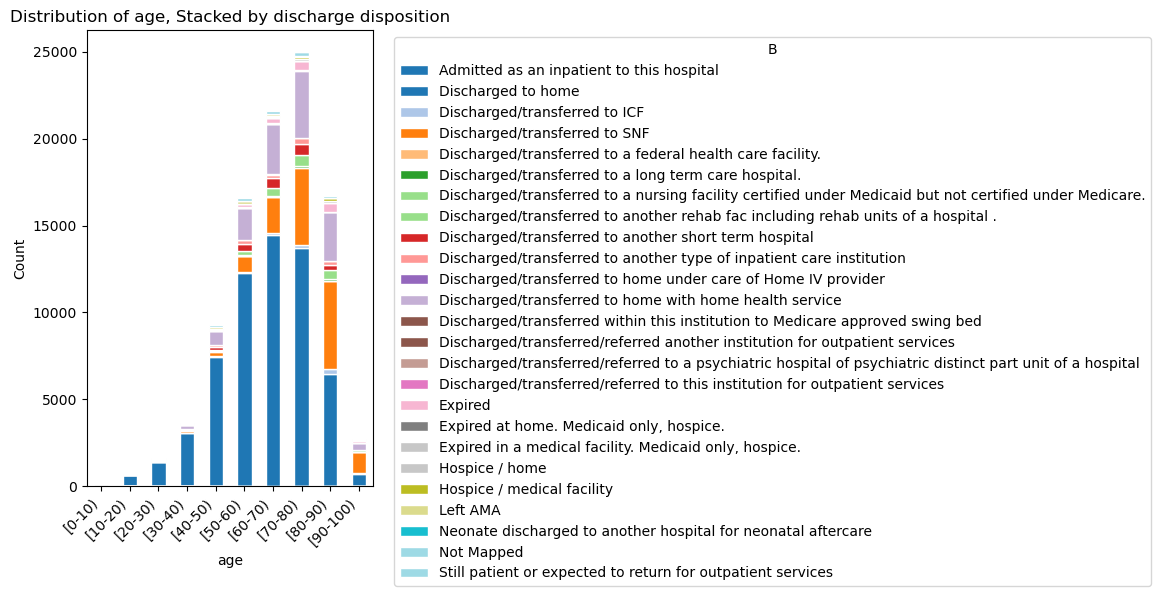

In [22]:
counts = pd.crosstab(diabetic_data["age"], diabetic_data["description_discharge_disposition"])

# Plot stacked bar chart
ax = counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="tab20",
    edgecolor="white"
)

ax.set_xlabel("age")
ax.set_ylabel("Count")
ax.set_title("Distribution of age, Stacked by discharge disposition")
ax.legend(title="B", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

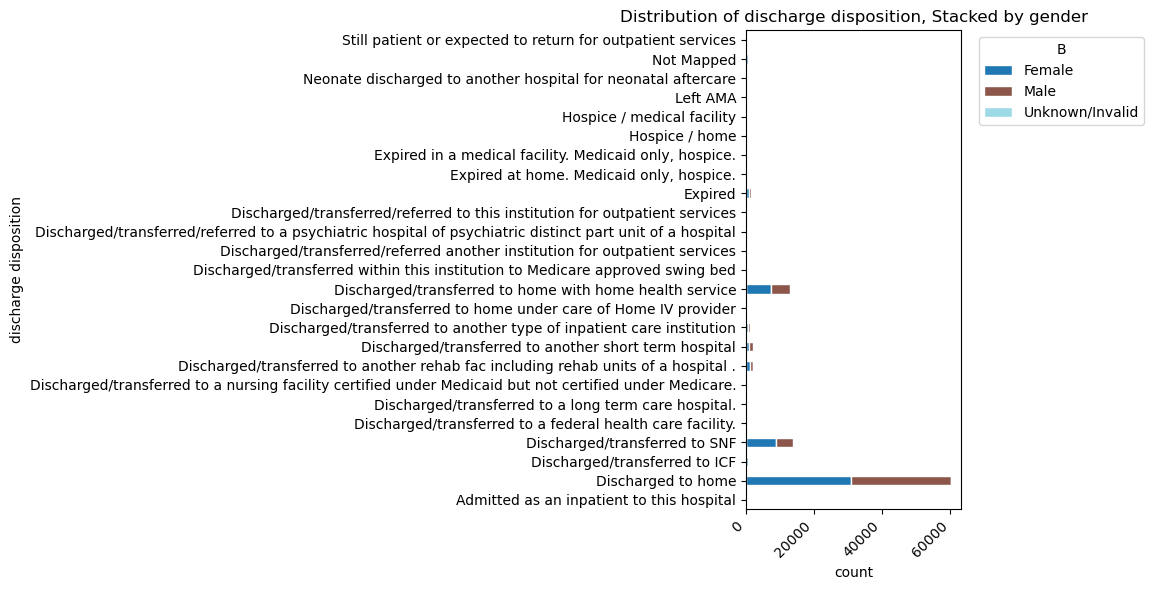

In [23]:
counts = pd.crosstab(diabetic_data["description_discharge_disposition"], diabetic_data["gender"])

# Plot stacked bar chart
ax = counts.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 6),
    colormap="tab20",
    edgecolor="white"
)

ax.set_xlabel("count")
ax.set_ylabel("discharge disposition")
ax.set_title("Distribution of discharge disposition, Stacked by gender")
ax.legend(title="B", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [24]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Assuming df has columns: A, B, gender
genders = diabetic_data["gender"].dropna().unique()

fig = make_subplots(
    rows=1,
    cols=2,
    specs=[[{"type": "domain"}, {"type": "domain"}]],
    subplot_titles=[str(g) for g in genders]
)

for i, gender in enumerate(genders[:2], start=1):
    subset = diabetic_data[diabetic_data["gender"] == gender]

    # Count flows from A to B
    flows = (
        subset.groupby(["description_admissions_source", "description_discharge_disposition"])
        .size()
        .reset_index(name="count")
    )

    # Create distinct source and target nodes
    sources = flows["description_admissions_source"].unique().tolist()
    targets = flows["description_discharge_disposition"].unique().tolist()

    labels = sources + targets

    source_map = {v: j for j, v in enumerate(sources)}
    target_map = {
        v: j + len(sources)
        for j, v in enumerate(targets)
    }

    fig.add_trace(
        go.Sankey(
            node=dict(
                label=[str(x) for x in labels],
                pad=15,
                thickness=20
            ),
            link=dict(
                source=flows["description_admissions_source"].map(source_map),
                target=flows["description_discharge_disposition"].map(target_map),
                value=flows["count"]
            )
        ),
        row=1,
        col=i
    )

fig.update_layout(
    title_text="Sankey Diagram: admission source → discharge disposition by Gender",
    width=1200,
    height=600,
    font_size=12
)

fig.show()

/var/folders/k5/7nk1477d5z3bkqm2lvczvt000000gn/T/ipykernel_92645/2174327491.py:18: UserWarning:

Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.



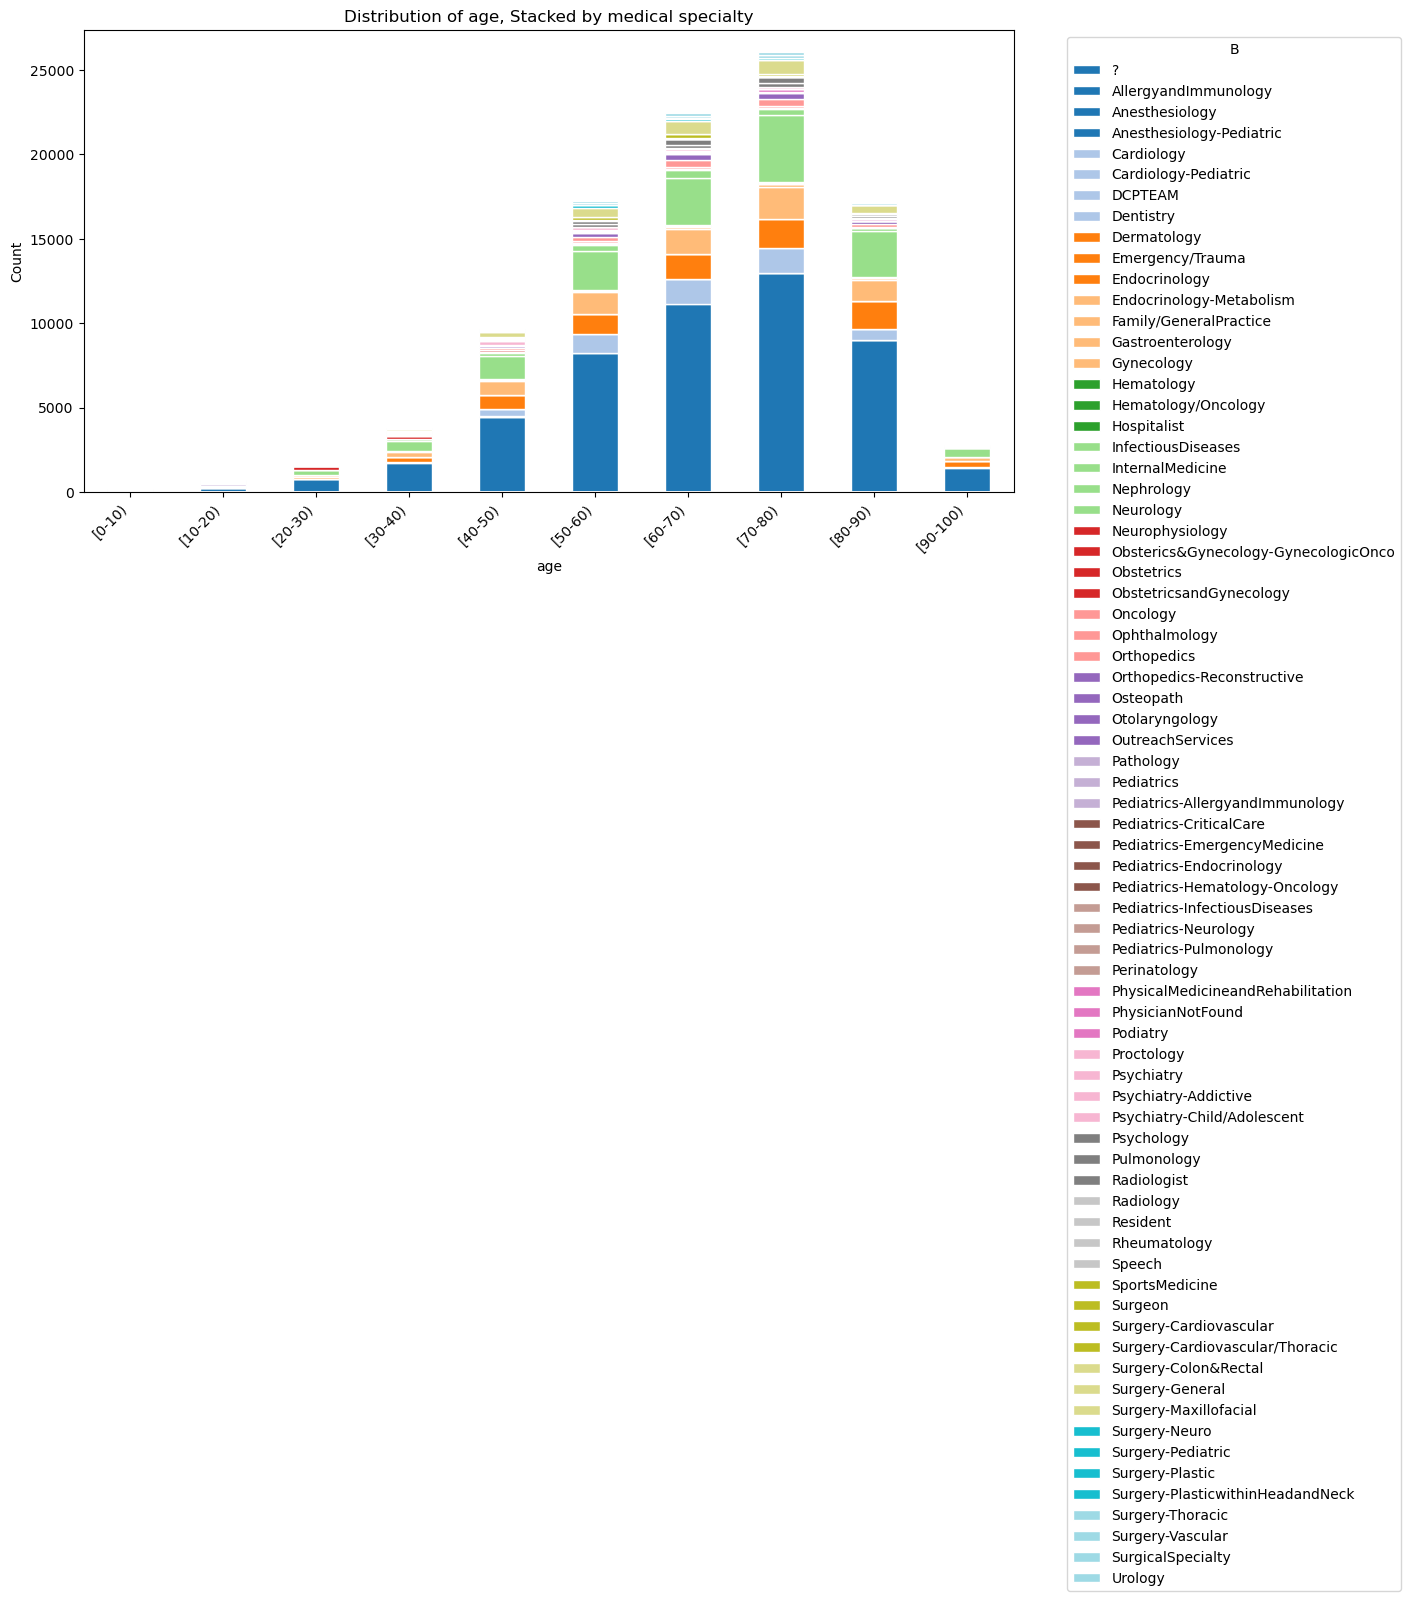

In [25]:
counts = pd.crosstab(diabetic_data["age"], diabetic_data["medical_specialty"])

# Plot stacked bar chart
ax = counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="tab20",
    edgecolor="white"
)

ax.set_xlabel("age")
ax.set_ylabel("Count")
ax.set_title("Distribution of age, Stacked by medical specialty")
ax.legend(title="B", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [26]:
diabetic_data["medical_specialty"].value_counts()

medical_specialty
?                                   49949
InternalMedicine                    14635
Emergency/Trauma                     7565
Family/GeneralPractice               7440
Cardiology                           5352
                                    ...  
SportsMedicine                          1
Dermatology                             1
Surgery-PlasticwithinHeadandNeck        1
Speech                                  1
Psychiatry-Addictive                    1
Name: count, Length: 73, dtype: int64

In [27]:
diabetic_data["gender"].value_counts()

gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

In [28]:
diabetic_data["race"].value_counts()

race
Caucasian          76099
AfricanAmerican    19210
?                   2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64

In [29]:
diabetic_data["age"].value_counts()

age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161
Name: count, dtype: int64

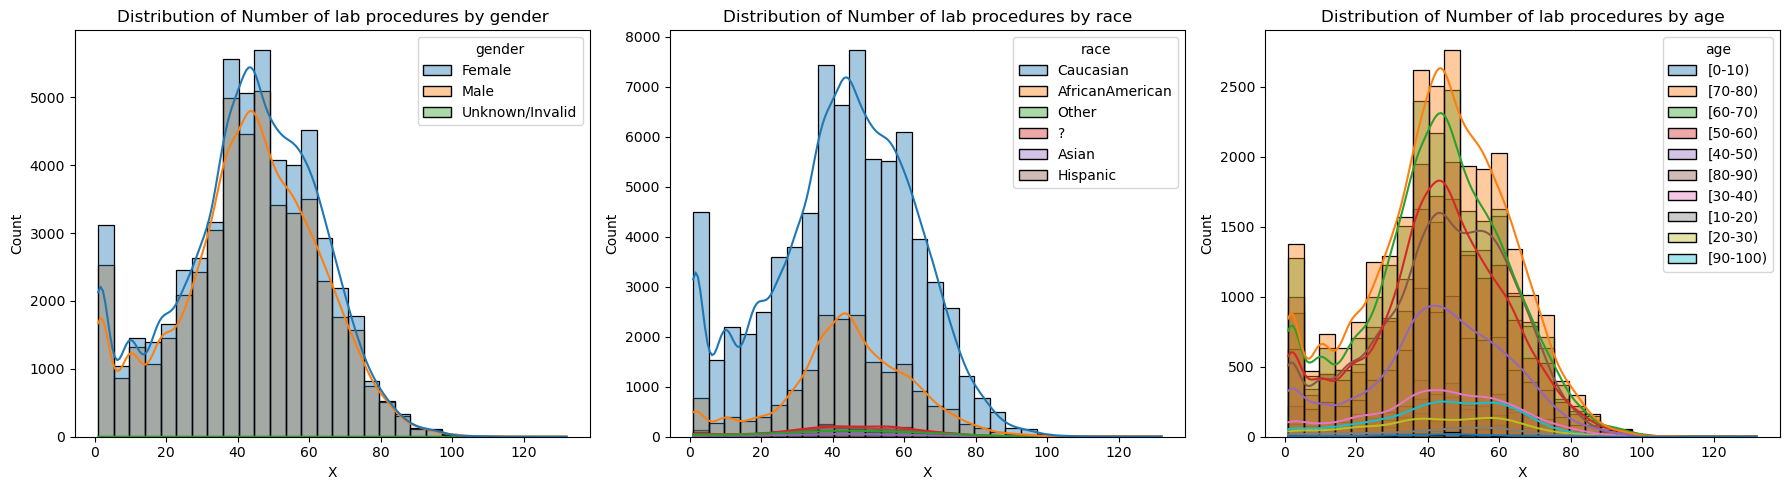

In [30]:
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, ["gender", "race", "age"]):
    sns.histplot(
        data=diabetic_data,
        x="num_lab_procedures",
        hue=col,
        bins=30,
        kde=True,
        multiple="layer",  # Overlapping histograms
        alpha=0.4,
        ax=ax
    )

    ax.set_title(f"Distribution of Number of lab procedures by {col}")
    ax.set_xlabel("X")
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

/Users/abhikbiswas/anaconda3/lib/python3.11/site-packages/seaborn/axisgrid.py:118: UserWarning:

The figure layout has changed to tight



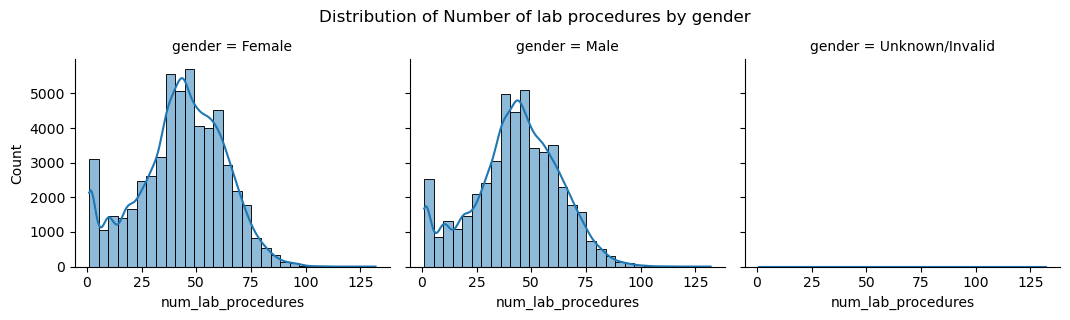

/Users/abhikbiswas/anaconda3/lib/python3.11/site-packages/seaborn/axisgrid.py:118: UserWarning:

The figure layout has changed to tight



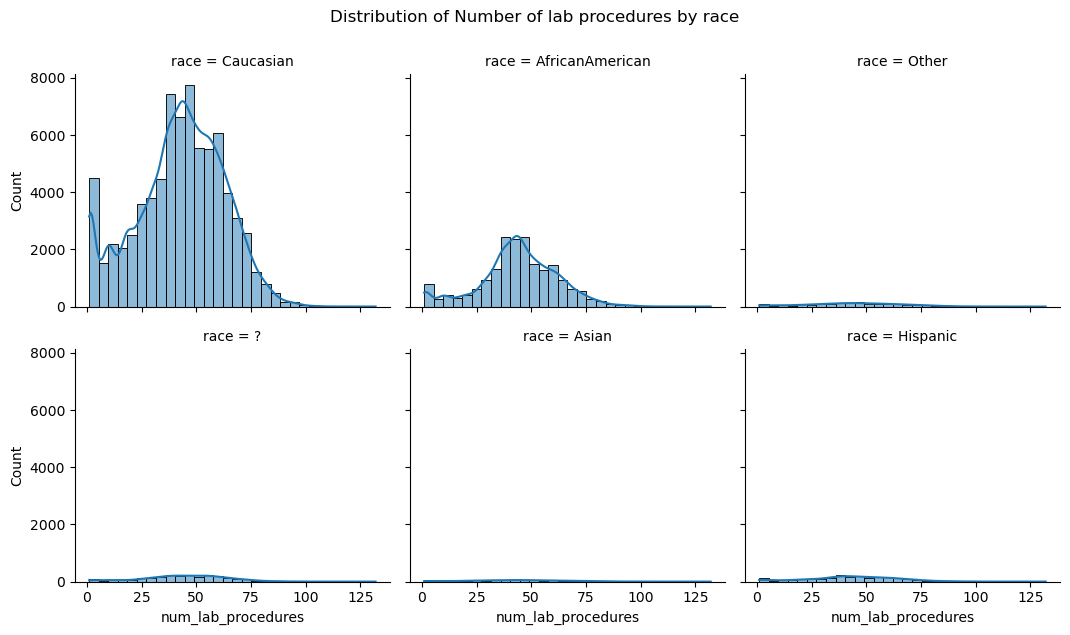

/Users/abhikbiswas/anaconda3/lib/python3.11/site-packages/seaborn/axisgrid.py:118: UserWarning:

The figure layout has changed to tight



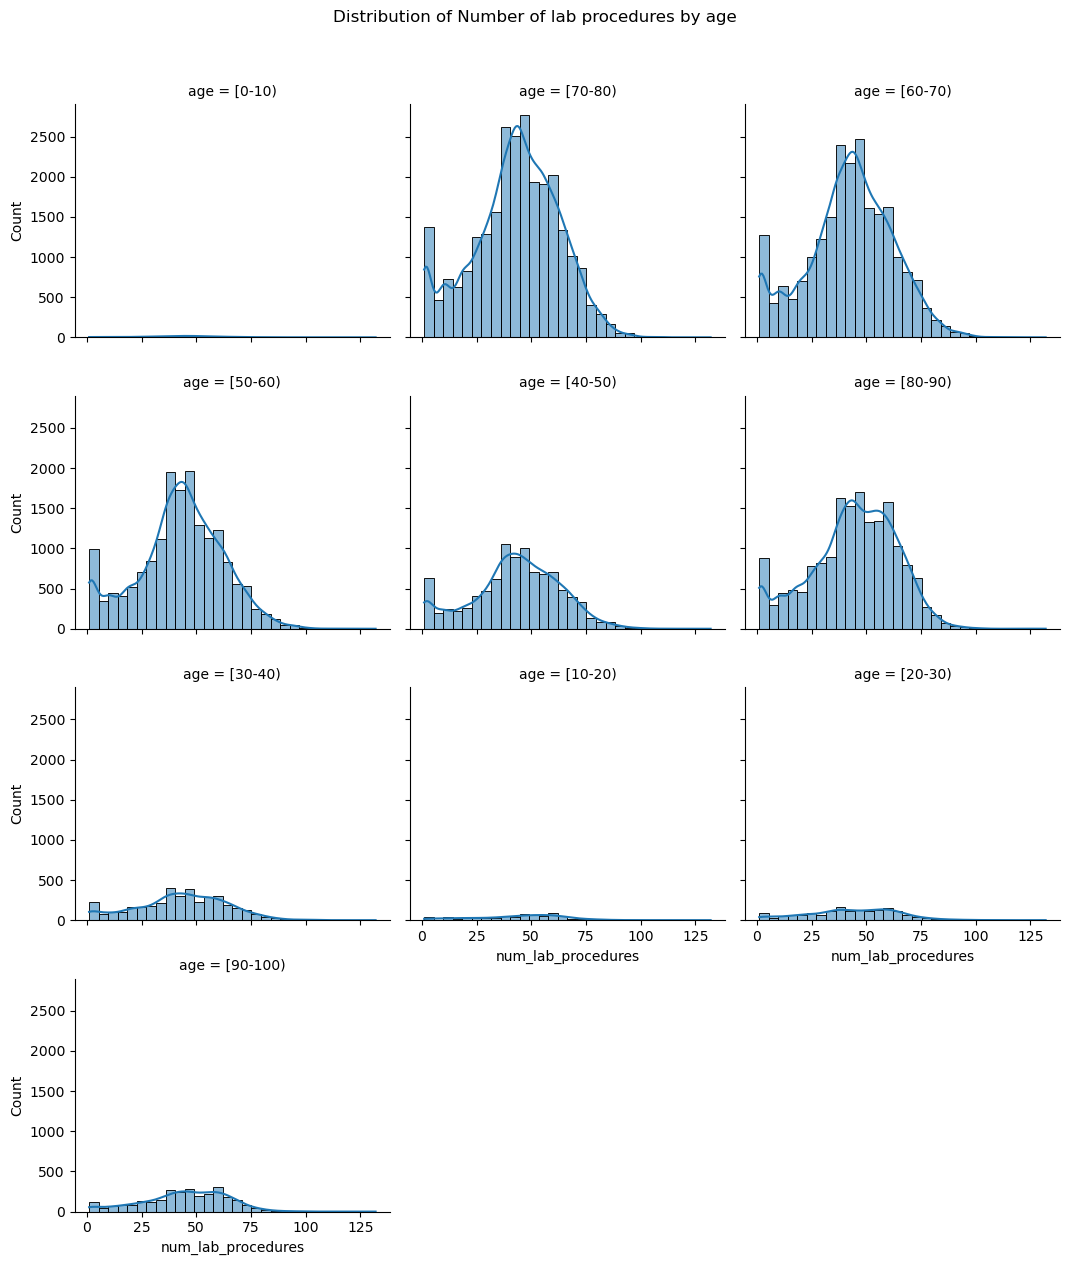

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in ["gender", "race", "age"]:
    g = sns.displot(
        data=diabetic_data,
        x="num_lab_procedures",
        col=col,
        col_wrap=3,
        bins=30,
        kde=True,
        height=3,
        aspect=1.2
    )

    g.fig.suptitle(f"Distribution of Number of lab procedures by {col}", y=1.05)
    plt.show()

In [32]:
diabetic_data["num_lab_procedures"].value_counts()

num_lab_procedures
1      3208
43     2804
44     2496
45     2376
38     2213
       ... 
121       1
107       1
120       1
129       1
126       1
Name: count, Length: 118, dtype: int64

In [33]:
diabetic_data["readmitted"].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

In [34]:
diabetic_data["payer_code"].value_counts()

payer_code
?     40256
MC    32439
HM     6274
SP     5007
BC     4655
MD     3532
CP     2533
UN     2448
CM     1937
OG     1033
PO      592
DM      549
CH      146
WC      135
OT       95
MP       79
SI       55
FR        1
Name: count, dtype: int64

## Primary Use Case
- Readmission Chances based on the encounter
- Who conducts the study
    - Insurance Company
         * What reserves they can allocate/ free up per claimant/ policyholder depending on chances of re-admission
         * Wellness programs for patients to keep them outof hospitals (based of personas of similar patients)
    - Hospitals
         * Proactive follow-up with high risk patients
         * Hospital resource allocation
    - Waterlily
         * Help the customer plan ahead for chances of re-admission
         * help them prepare for a readmission in the future
## Secondary cases
- checking if payer code influences the number of lab procedures/ procedures
    - Government agencies
         * Regulate insurance companies and HCPs
         * Penalties for providers for jacking up the prices/ lab procedures unnecessarily
    - Waterlily
         * Depending on the insurance carriers, we can provide customized estimates of future costs
         * Suggest lab procedures to be done regularly to avoid readmissions (based on the carrier
- Checking the time in hospital for a patient, or predicting for how long a patient would be in the hospital
        * Help plan patients for their future costs
        * Estimate their time in hospitals/ HCFs upon admissions...

In [35]:
diabetic_data.head(2)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,description_admissions_source,description_discharge_disposition,description_admission_type
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO,Physician Referral,Not Mapped,NaN
1,1968528,720936,Caucasian,Female,[70-80),?,6,25,1,10,?,Surgery-Cardiovascular/Thoracic,56,2,24,0,0,0,440,413,250.52,9,NaN,>7,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,>30,Physician Referral,Not Mapped,NaN


In [36]:
diabetic_data["diag_1"].nunique()

717

In [37]:
diabetic_data["weight"].value_counts()

weight
?            98569
[75-100)      1336
[50-75)        897
[100-125)      625
[125-150)      145
[25-50)         97
[0-25)          48
[150-175)       35
[175-200)       11
>200             3
Name: count, dtype: int64

In [38]:
diabetic_data.drop(["encounter_id", 
                   "patient_nbr", 
                   "admission_type_id", 
                   "admission_source_id", 
                   "discharge_disposition_id",
                   "medical_specialty", 
                   "diag_1", "diag_2", "diag_3", 
                   "max_glu_serum", "A1Cresult"], axis=1, inplace=True)

In [39]:
diabetic_data.head(2)

,race,gender,age,weight,time_in_hospital,payer_code,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,description_admissions_source,description_discharge_disposition,description_admission_type
0,Caucasian,Female,[0-10),?,1,?,41,0,1,0,0,0,1,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO,Physician Referral,Not Mapped,NaN
1,Caucasian,Female,[70-80),?,10,?,56,2,24,0,0,0,9,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,>30,Physician Referral,Not Mapped,NaN


In [40]:
diabetic_data["weight_imputed"] = diabetic_data["weight"].copy()

for cols in [["age", "race", "gender"], ["age", "race"], ["age"]]:
    group_mode = diabetic_data.groupby(cols)["weight"].transform(
        lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
    )

    diabetic_data["weight_imputed"] = diabetic_data["weight_imputed"].fillna(group_mode)

# Global mode fallback
diabetic_data["weight_imputed"] = diabetic_data["weight_imputed"].fillna(
    diabetic_data["weight"].mode().iloc[0]
)

In [41]:
diabetic_data.drop("weight", axis=1, inplace=True)

In [42]:
diabetic_data.drop("diabetesMed", axis=1, inplace=True)

In [43]:
diabetic_data

,race,gender,age,time_in_hospital,payer_code,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,readmitted,description_admissions_source,description_discharge_disposition,description_admission_type,weight_imputed
0,Caucasian,Female,[0-10),1,?,41,0,1,0,0,0,1,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO,Physician Referral,Not Mapped,NaN,?
1,Caucasian,Female,[70-80),10,?,56,2,24,0,0,0,9,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,>30,Physician Referral,Not Mapped,NaN,?
2,AfricanAmerican,Female,[60-70),9,?,60,5,17,0,0,0,8,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO,Physician Referral,Not Mapped,NaN,?
3,Caucasian,Male,[60-70),4,?,47,0,15,0,0,0,8,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,NO,Physician Referral,Not Mapped,NaN,?
4,AfricanAmerican,Female,[50-60),1,?,50,0,8,0,0,0,8,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,>30,Physician Referral,Not Mapped,NaN,?
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101761,Caucasian,Male,[40-50),1,HM,36,0,8,0,0,0,5,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,NO,Emergency Room,Expired,Trauma Center,?
101762,Caucasian,Female,[80-90),1,MC,1,2,5,0,0,0,7,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,NO,Emergency Room,Expired,Trauma Center,?
101763,Caucasian,Female,[50-60),11,CP,70,6,29,0,0,0,9,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,NO,Emergency Room,Discharged/transferred to another rehab fac in...,Trauma Center,?
101764,Caucasian,Male,[50-60),8,CP,69,2,26,0,0,0,9,Steady,No,No,No,Steady,No,No,No,No,Steady,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,NO,Emergency Room,Discharged/transferred to another rehab fac in...,Trauma Center,?


In [44]:
diabetic_data.columns

Index(['race', 'gender', 'age', 'time_in_hospital', 'payer_code',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient',
       'number_diagnoses', 'metformin', 'repaglinide', 'nateglinide',
       'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide',
       'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose',
       'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton',
       'insulin', 'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'readmitted',
       'description_admissions_source', 'description_discharge_disposition',
       'description_admission_type', 'weight_imputed'],
      dtype='object')

In [45]:
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.pipeline import Pipeline

# Define categorical columns
ordinal_cols = ["age", "weight_imputed"]
onehot_cols = ["race", "gender", "payer_code", 'metformin', 'repaglinide', 'nateglinide',
       'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide',
       'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose',
       'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton',
       'insulin', 'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change']

In [46]:
from sklearn.model_selection import train_test_split

In [47]:
diabetic_data["readmitted"].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

In [48]:
X = diabetic_data.drop(columns=["readmitted"])
y = diabetic_data["readmitted"]

# 70% Train, 15% Validation, 15% Test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

# Split remaining 30% equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

# Verify class distributions
for name, target in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"\n{name}: {len(target)} samples")
    print(target.value_counts(normalize=True).round(3))


Train: 71236 samples
readmitted
NO     0.539
>30    0.349
<30    0.112
Name: proportion, dtype: float64

Validation: 15265 samples
readmitted
NO     0.539
>30    0.349
<30    0.112
Name: proportion, dtype: float64

Test: 15265 samples
readmitted
NO     0.539
>30    0.349
<30    0.112
Name: proportion, dtype: float64


In [49]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y_train = le.fit_transform(y_train)
y_val = le.transform(y_val)
y_test = le.transform(y_test)

In [51]:
import xgboost as xgb

print(xgb.__version__)

3.2.0


In [54]:
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# Categorical columns
categorical_cols = ordinal_cols + onehot_cols + ["description_admissions_source", "description_discharge_disposition", "description_admission_type"]

# Convert to categorical dtype
for X in [X_train, X_val, X_test]:
    X[categorical_cols] = X[categorical_cols].astype("category")

model = xgb.XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    enable_categorical=True,
    tree_method="hist",
    n_estimators=1000,
    max_depth=5,
    learning_rate=0.05,
    eval_metric="mlogloss",
    early_stopping_rounds=50,
    random_state=42
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=50,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=1000, n_jobs=None, num_class=3, ...)

In [55]:
# Predictions
y_pred = model.predict(X_test)

# Evaluation
print("Best iteration:", model.best_iteration)
print("Macro F1:", f1_score(y_test, y_pred, average="macro"))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Best iteration: 209
Macro F1: 0.4067827783297966

Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.04      0.07      1704
           1       0.52      0.37      0.44      5332
           2       0.62      0.85      0.72      8229

    accuracy                           0.59     15265
   macro avg       0.57      0.42      0.41     15265
weighted avg       0.58      0.59      0.55     15265


Confusion Matrix:
[[  62  624 1018]
 [  28 1998 3306]
 [  20 1210 6999]]


In [57]:
model.save_model("xgboost_model.json")

In [56]:
# from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
# from sklearn.metrics import classification_report, f1_score
# import xgboost as xgb

# model = xgb.XGBClassifier(
#     objective="multi:softprob",
#     num_class=3,
#     enable_categorical=True,
#     tree_method="hist",
#     eval_metric="mlogloss",
#     random_state=42,
#     n_jobs=1
# )

# param_dist = {
#     "n_estimators": [200, 400, 600, 800, 1000],
#     "max_depth": [3, 4, 5, 6, 8],
#     "learning_rate": [0.01, 0.03, 0.05, 0.1],
#     "subsample": [0.7, 0.8, 0.9, 1.0],
#     "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
#     "min_child_weight": [1, 3, 5, 7],
#     "gamma": [0, 0.1, 0.3, 0.5],
#     "reg_alpha": [0, 0.1, 1, 5],
#     "reg_lambda": [1, 5, 10]
# }

# cv = StratifiedKFold(
#     n_splits=5,
#     shuffle=True,
#     random_state=42
# )

# random_search = RandomizedSearchCV(
#     estimator=model,
#     param_distributions=param_dist,
#     n_iter=50,
#     scoring="f1_macro",
#     cv=cv,
#     n_jobs=-1,
#     verbose=2,
#     random_state=42,
#     refit=True
# )

# random_search.fit(X_train, y_train)

# # Best model and parameters
# best_model = random_search.best_estimator_

# print("Best Parameters:", random_search.best_params_)
# print("Best CV Macro F1:", random_search.best_score_)

# # Validation evaluation
# y_val_pred = best_model.predict(X_val)

# print("Validation Macro F1:", f1_score(y_val, y_val_pred, average="macro"))
# print(classification_report(y_val, y_val_pred))

# # Save model
# best_model.save_model("xgboost_tuned.json")

In [58]:
import json

sample = X_test.iloc[0].to_dict()

with open("sample.json", "w") as f:
    json.dump(sample, f, default=str, indent=2)